In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
plt.rcParams['figure.figsize'] = (7, 3.5)

In [2]:
def gram_matrix(N, Delta):
    return scipy.linalg.toeplitz([np.sinc(Delta*k) for k in range(N)])

def dpss_window(N, Delta):
    w = scipy.signal.windows.dpss(N, 0.5 * Delta * N)
    return w / np.sqrt(np.sum(w**2))

def dpss_window_eigval_squared(N, Delta):
    return np.sum((gram_matrix(N, Delta) @ dpss_window(N, Delta))**2)

In [3]:
ks = np.arange(3, 14)
Ns = 2**ks
Delta_factors = np.array([1/4, 1/2, 1, 2, 4])
matched_filter_loss = np.array([[10*np.log10(np.sum(gram_matrix(N, Delta_factor/N))) - 20*np.log10(N)
                                 for Delta_factor in Delta_factors] for N in Ns])
dpss_matched_filter_loss = np.array([[5*np.log10(dpss_window_eigval_squared(N, Delta_factor/N)) - 10*np.log10(N)
                                 for Delta_factor in Delta_factors] for N in Ns])

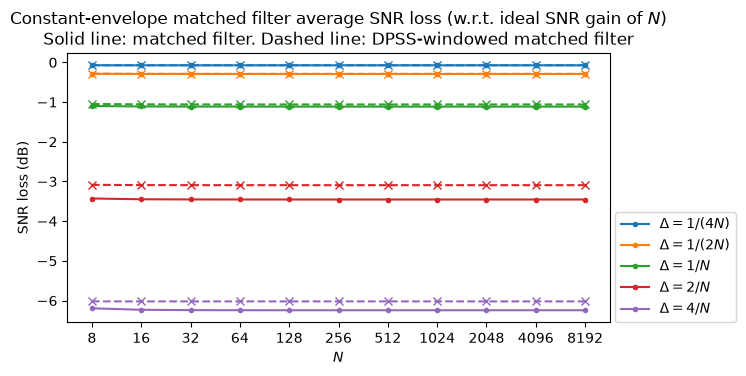

In [4]:
plt.plot(matched_filter_loss, '.-')
plt.gca().set_prop_cycle(None)
plt.plot(dpss_matched_filter_loss, 'x--')
plt.xticks(np.arange(Ns.size), Ns)
plt.xlabel('$N$')
plt.ylabel('SNR loss (dB)')

def df_label(Df):
    if Df > 1:
        return f'$\\Delta = {Df:.0f}/N$'
    if Df < 1 :
        return f'$\\Delta = 1/({1/Df:.0f}N)$'
    else:
        return '$\\Delta = 1/N$'

plt.legend([df_label(Df) for Df in Delta_factors], loc=(1.01, 0))
plt.title('Constant-envelope matched filter average SNR loss (w.r.t. ideal SNR gain of $N$)\n'
          'Solid line: matched filter. Dashed line: DPSS-windowed matched filter');

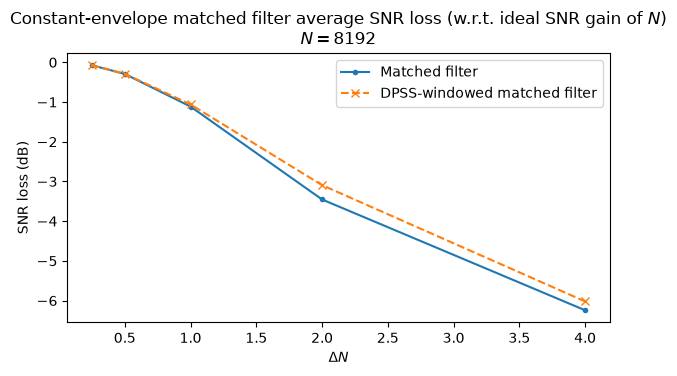

In [5]:
plt.plot(Delta_factors, matched_filter_loss[-1], '.-')
plt.plot(Delta_factors, dpss_matched_filter_loss[-1], 'x--')
plt.xlabel('$\\Delta N$')
plt.ylabel('SNR loss (dB)')
plt.legend(['Matched filter', 'DPSS-windowed matched filter'])
plt.title(f'Constant-envelope matched filter average SNR loss (w.r.t. ideal SNR gain of $N$)\n$N = {Ns[-1]}$');

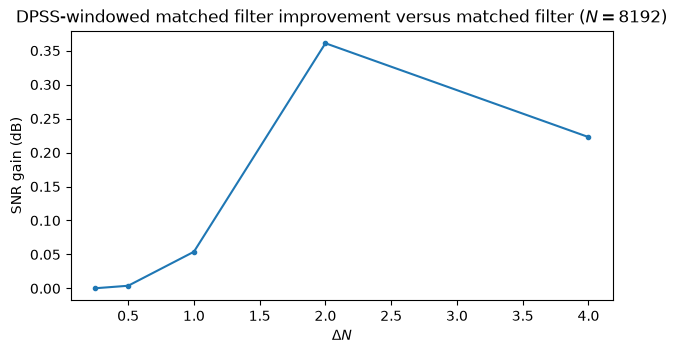

In [6]:
plt.plot(Delta_factors, dpss_matched_filter_loss[-1] -  matched_filter_loss[-1], '.-')
plt.xlabel('$\\Delta N$')
plt.ylabel('SNR gain (dB)')
plt.title(f'DPSS-windowed matched filter improvement versus matched filter ($N = {Ns[-1]}$)');

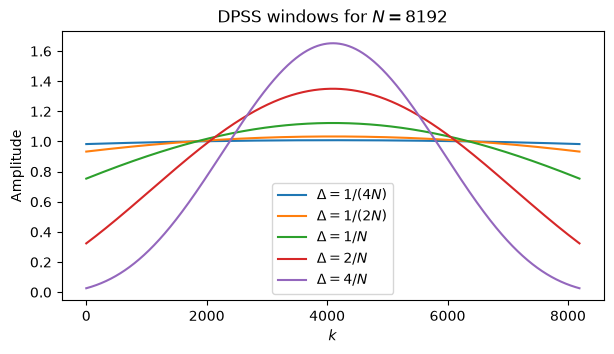

In [7]:
for Df in Delta_factors:
    plt.plot(dpss_window(Ns[-1], Df/Ns[-1]) * np.sqrt(Ns[-1]), label=df_label(Df))
plt.legend()
plt.xlabel('$k$')
plt.ylabel('Amplitude')
plt.title(f'DPSS windows for $N = {Ns[-1]}$');